# Chapitre 13 - Les k plus proches voisins (cours 2)

Ce second notebook traite des **k plus proches voisins** (k-ppv) :

1. la règle des k-ppv et le choix de $k$ (figures 13.3 et 13.4 du livre) ;
2. le résultat de Cover et Hart : asymptotiquement, le 1-ppv fait au plus deux fois
   l'erreur de Bayes ;
3. les **métriques invariantes** et la **distance tangente**, illustrées sur les chiffres
   manuscrits (figures 13.9-13.11, tableau 13.1) ;
4. le fléau de la dimension et les **métriques adaptatives** (DANN, figures 13.12-13.15),
   ainsi que la réduction de dimension globale ;
5. le **coût calculatoire** et les méthodes de condensation (section 13.5).

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl.plotting import decision_grid
from esl import datasets
from esl import ch13_prototypes as cp
from matplotlib.colors import ListedColormap
set_style()
PURPLE = COLORS[6]

## 1. La règle des k plus proches voisins

Les k-ppv sont une méthode **à mémoire** : aucun modèle n'est ajusté, on conserve
tout l'échantillon d'apprentissage. Pour classer un point $x_0$ :

1. on calcule les distances $d_{i} = \|x_i - x_0\|$ (éq. (13.1) du livre), après
   avoir standardisé les variables ;
2. on retient les $k$ points $x_{(1)}, \dots, x_{(k)}$ les plus proches ;
3. on prédit la classe **majoritaire** parmi leurs étiquettes (égalités tranchées au
   hasard).

Avec $k = 1$, chaque point d'apprentissage est son propre prototype : c'est le cas
extrême des méthodes du notebook précédent.

> **Intuition (biais et variance).** Le vote des $k$ voisins estime localement les
> probabilités $p_j(x_0) = \Pr(G = j \mid X = x_0)$ par des fréquences.
> * $k$ petit : on n'utilise que des points très proches de $x_0$ (faible **biais**),
>   mais la fréquence repose sur peu d'observations (forte **variance**) ;
> * $k$ grand : la moyenne est plus stable, mais elle mélange des points éloignés où
>   les probabilités sont différentes (biais).
>
> Le nombre « effectif » de paramètres est de l'ordre de $N/k$ (autant que de
> voisinages disjoints).

## 2. Figure 13.3 : la simulation à trois classes

Nous reprenons la simulation à trois classes du notebook précédent (même graine), et
la même fonction de tracé des régions.

In [2]:
rng = np.random.RandomState(2)
base = np.array([[-1.5, 1.0], [1.5, 1.0], [0.0, -1.5]])
means3 = [b + 0.8 * rng.randn(10, 2) for b in base]
sigma2_3 = 0.2
X3, y3 = cp.sample_gaussian_mixture(means3, 100, sigma2_3, rng)
X3_test, y3_test = cp.sample_gaussian_mixture(means3, 3000, sigma2_3, rng)
bayes3_rule = lambda G: cp.mixture_posterior(G, means3, sigma2_3).argmax(1)
print("Erreur de Bayes : %.3f" % np.mean(bayes3_rule(X3_test) != y3_test))


def plot_regions(ax, predict, X, y, bayes=None, xlim=(-4, 4), ylim=(-4, 4), n=250, ncls=3):
    xx, yy, grid = decision_grid(xlim, ylim, n)
    cmap = ListedColormap(COLORS[:ncls])
    Z = predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(ncls + 1) - 0.5, cmap=cmap, alpha=0.15)
    ax.contour(xx, yy, Z, levels=np.arange(ncls) + 0.5, colors="k", linewidths=1)
    if bayes is not None:
        ax.contour(xx, yy, bayes(grid).reshape(xx.shape), levels=np.arange(ncls) + 0.5,
                   colors=PURPLE, linewidths=1.5, linestyles="--")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap, s=12, alpha=0.8, vmin=0, vmax=ncls - 1)
    ax.set(xlim=xlim, ylim=ylim, xlabel="$X_1$", ylabel="$X_2$")

Erreur de Bayes : 0.073


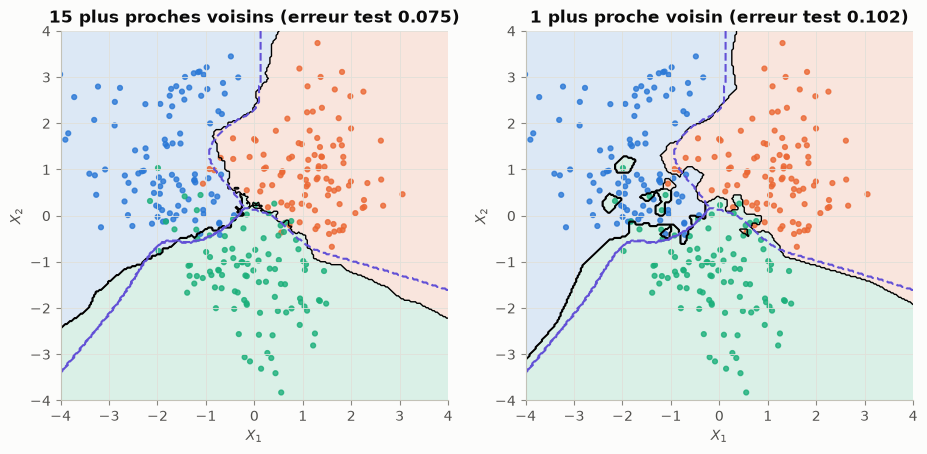

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, k in zip(axes, (15, 1)):
    err = np.mean(cp.knn_predict(X3, y3, X3_test, k) != y3_test)
    plot_regions(ax, lambda G, k=k: cp.knn_predict(X3, y3, G, k), X3, y3, bayes3_rule)
    ax.set_title("%d plus proche%s voisin%s (erreur test %.3f)"
                 % (k, "s" if k > 1 else "", "s" if k > 1 else "", err))
plt.show()

Avec 15 voisins, la frontière est assez régulière et suit bien celle de Bayes ; avec
un seul voisin elle est très découpée : des îlots entourent les points isolés. Le
1-ppv a une erreur d'apprentissage nulle (chaque point est son propre voisin), ce qui
ne dit rien de son erreur test.

## 3. Figure 13.4 : choix de k sur les données « mixture »

Sur la simulation à deux classes du chapitre 2, nous traçons en fonction de $k$ :

* l'erreur d'**apprentissage** ;
* l'erreur **test** (10 000 points simulés selon le vrai modèle) ;
* l'erreur de **validation croisée à 10 blocs**, avec une barre d'erreur standard :
  l'erreur VC est la moyenne de 10 erreurs de blocs $e_1, \dots, e_{10}$, on l'accompagne
  de $\widehat{\mathrm{se}} = s/\sqrt{10}$ où $s$ est l'écart-type empirique des $e_b$.

In [ ]:
mix = datasets.load_mixture_example()
Xm, ym = mix["x"], mix["y"]
means_m = [mix["means"][:10], mix["means"][10:]]
Xm_test, ym_test = cp.sample_gaussian_mixture(means_m, 5000, 0.2, np.random.RandomState(0))
bayes_m_rule = lambda G: cp.mixture_posterior(G, means_m, 0.2).argmax(1)
bayes_m = np.mean(bayes_m_rule(Xm_test) != ym_test)

ks = np.arange(1, 31)
err_train = (cp.knn_from_dists(cp.sq_dists(Xm, Xm), ym, ks) != ym).mean(1)
err_test = (cp.knn_from_dists(cp.sq_dists(Xm_test, Xm), ym, ks) != ym_test).mean(1)
cv_mean, cv_se = cp.knn_cv_error(Xm, ym, ks, n_folds=10, rng=np.random.RandomState(1))